# EDA - freight rates
Quick look at the data before modelling. Plots come from `src/plots.py` so the report uses the same ones.

In [1]:
import sys; sys.path.insert(0, '..')
%matplotlib inline
import numpy as np, pandas as pd
from src import config as C, plots
from src.data import load, audit, clean, lane_rpm_resid
tr, va = load(C.TRAIN_CSV), load(C.VAL_CSV)
print(tr.shape, tr.date.min().date(), '->', tr.date.max().date())
print(va.shape, va.date.min().date(), '->', va.date.max().date())
tr.head()

(48000, 14) 2025-01-01 -> 2025-10-31
(12000, 13) 2025-11-01 -> 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Data quality
Every check w/ counts. Same function `main.py` uses.

In [2]:
log = []
audit(tr, 'train_test.csv', log); audit(va, 'validation.csv', log)
pd.DataFrame(log)

,file,issue,count,action
0,train_test.csv,rows,48000,-
1,train_test.csv,duplicate load_id,0,none found
2,train_test.csv,duplicate rows (ex load_id),0,none found
3,train_test.csv,missing weight,300,impute w/ train median per equipment
4,train_test.csv,negative weight,292,"abs() - same dist + same rpm as positives, sig..."
5,train_test.csv,"weight at 47,500 cap",1204,"keep, looks like clipping"
6,train_test.csv,missing market_index,374,not used by final model
7,train_test.csv,distance at 70 mi floor,48,"keep, consistent per lane"
8,train_test.csv,distance > 2x great-circle,22,"keep, all short lanes on the 70 mi floor"
9,train_test.csv,lat clipped at 25.5,0,"keep, distance carries the real info"


Negative weights: abs values look exactly like the positive ones and the rpm is the same -> sign glitch, abs() is fine.

In [3]:
neg = tr.weight < 0
rpm = tr.posted_rate / tr.distance
pd.DataFrame({'abs weight (neg rows)': tr.weight[neg].abs().describe(), 'weight (pos rows)': tr.weight[~neg].describe()}).round(0).T.assign(
    median_rpm=[rpm[neg].median(), rpm[~neg].median()])

,count,mean,std,min,25%,50%,75%,max,median_rpm
abs weight (neg rows),292.0,31724.0,8263.0,5000.0,25928.0,31822.0,37284.0,47500.0,2.156653
weight (pos rows),47408.0,31415.0,7995.0,5000.0,25922.0,31494.0,37063.0,47500.0,2.145241


## Target
Rates are right-skewed and mostly driven by distance, so I model log(rate per mile) and multiply back.

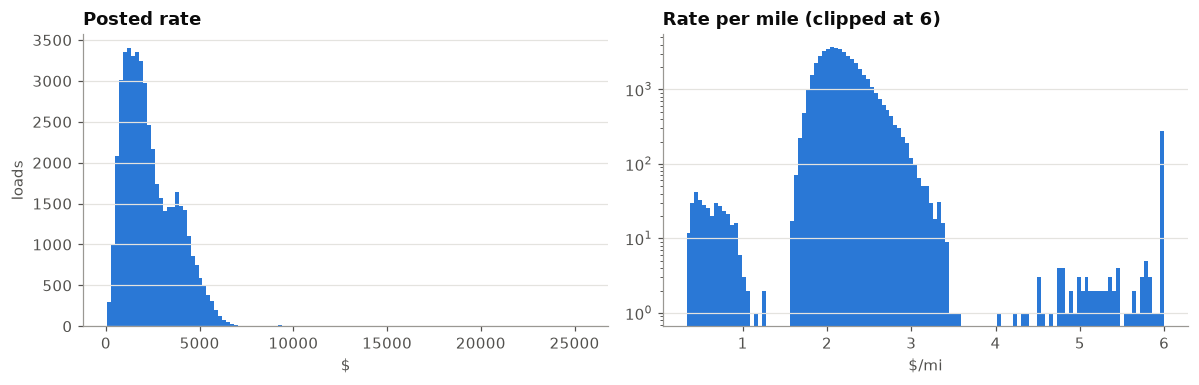

In [4]:
tr = clean(tr); plots.target_dist(tr);

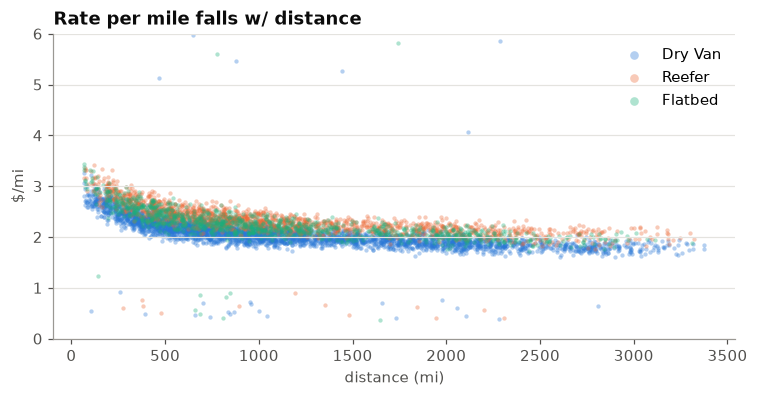

In [5]:
plots.rpm_vs_distance(tr);

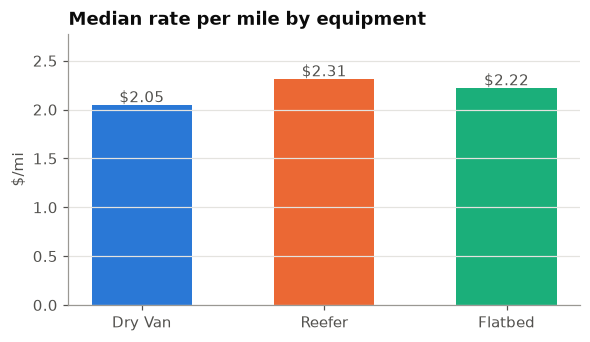

In [6]:
plots.equipment_effect(tr);

## Outliers
~1.4% of rows sit at ~0.3x or ~3.5x their lane median - two clean clusters, looks like label noise, not real market moves. Kills RMSE, so MAE/MAPE is the fairer view.

>1.8x: 328  <1/1.8x: 320


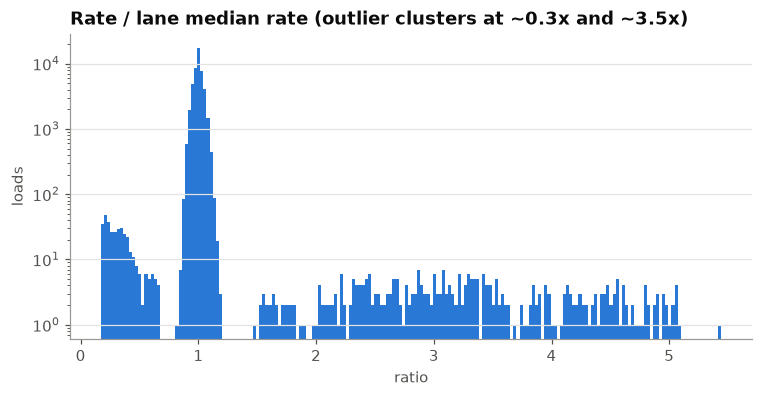

In [7]:
plots.outliers(tr)
r = np.exp(lane_rpm_resid(tr)); print('>1.8x:', (r > 1.8).sum(), ' <1/1.8x:', (r < 1/1.8).sum())

## Trend over time
Level vs lane norm is a hump (low in Jan, peaks Jun, back down by Aug) - not a straight drift. market_index has the same shape but a much bigger swing, and the relationship doesn't hold out of time (tested in validation).

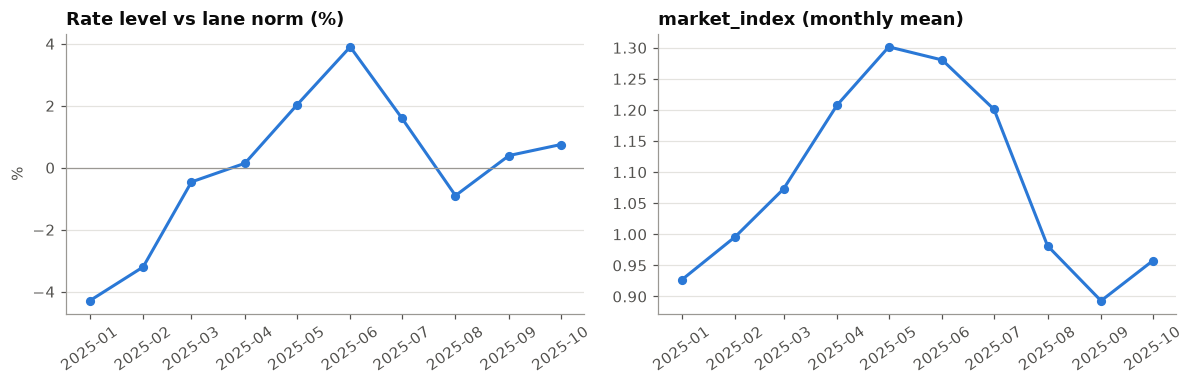

In [8]:
plots.monthly_trend(tr);

In [9]:
print(va.groupby(va.date.dt.to_period('M')).market_index.mean())  # nov/dec mi back near jan levels

date
2025-11    0.918716
2025-12    0.934690
Freq: M, Name: market_index, dtype: float64


## Day of week
Small effect (~2% between Mon and Thu).

In [10]:
rpm.groupby(tr.date.dt.day_name()).median().round(3)

date
Friday       2.157
Monday       2.126
Saturday     2.132
Sunday       2.127
Thursday     2.171
Tuesday      2.139
Wednesday    2.163
dtype: float64

## Unseen cities / lanes in validation
8 cities only show up in validation -> can't rely on city IDs alone, keep lat/lon + distance.

In [11]:
ct = set(tr.pickup) | set(tr.delivery); cv = set(va.pickup) | set(va.delivery)
print('val-only cities:', sorted(cv - ct))
m = ~va.pickup.isin(ct) | ~va.delivery.isin(ct)
seen_lanes = set(zip(tr.pickup, tr.delivery))
print('val rows w/ unseen city:', m.sum(), f'({m.mean():.1%})')
print('val rows on unseen lane:', sum(k not in seen_lanes for k in zip(va.pickup, va.delivery)))

val-only cities: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
val rows w/ unseen city: 1447 (12.1%)
val rows on unseen lane: 1461


Coordinates look synthetic/clipped (Laredo lat=25.5, Boston/Providence lon=-69.5) but each city has exactly one coord pair, and distance is consistent per lane.

## December lane: Lexington -> Fort Wayne

In [12]:
lane = tr[(tr.pickup == 'Lexington') & (tr.delivery == 'Fort Wayne')]
lane.groupby('equipment').posted_rate.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
equipment,,,,,,,,
Dry Van,21.0,823.3,46.2,757.9,791.2,807.9,849.2,934.4
Flatbed,3.0,880.6,37.9,844.1,861.0,877.8,898.8,919.8
Reefer,8.0,934.9,24.6,901.4,916.7,934.5,949.6,973.8


In [13]:
lane[lane.equipment == 'Dry Van'][['date', 'distance', 'weight', 'posted_rate']]

,date,distance,weight,posted_rate
654,2025-01-05,358.3,22567.0,757.93
1571,2025-01-10,358.2,31556.0,788.08
2821,2025-01-18,362.1,27842.0,768.22
3913,2025-01-25,357.5,37102.0,807.89
6788,2025-02-12,376.8,41021.0,870.22
8369,2025-02-23,355.1,27601.0,791.25
10557,2025-03-08,359.9,24178.0,791.31
11817,2025-03-16,367.6,16195.0,806.54
12207,2025-03-19,363.1,27600.0,810.96
14448,2025-04-01,362.8,25383.0,786.50
